<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Missing Values**


Estimated time needed: **30** minutes


Data wrangling is the process of cleaning, transforming, and organizing data to make it suitable for analysis. Finding and handling missing values is a crucial step in this process to ensure data accuracy and completeness. In this lab, you will focus exclusively on identifying and handling missing values in the dataset.


## Objectives


After completing this lab, you will be able to:


-   Identify missing values in the dataset.

- Quantify missing values for specific columns.

- Impute missing values using various strategies.


## Hands on Lab


##### Setup: Install Required Libraries


In [1]:
# The original `!pip install` magic commands only run in Jupyter environments.
# They are kept below as comments. Use subprocess instead so the packages are
# installed with the same Python interpreter that is selected in VS Code.
# !pip install pandas
# !pip install matplotlib
# !pip install seaborn
import importlib.util
import subprocess
import sys

def install(package, import_name=None):
    """Quietly pip-install a package if it is not already available."""
    import_name = import_name or package
    try:
        spec = importlib.util.find_spec(import_name)
    except (ImportError, ModuleNotFoundError, ValueError):
        spec = None
    if spec is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package])

install('pandas', 'pandas')
install('matplotlib', 'matplotlib')
install('seaborn', 'seaborn')

##### Import Necessary Modules:


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Tasks


<h2>1. Load the Dataset</h2>
<p>
We use the <code>pandas.read_csv()</code> function for reading CSV files. However, in this version of the lab, which operates on JupyterLite, the dataset needs to be downloaded to the interface using the provided code below.
</p>


The functions below will download the dataset into your browser:



In [3]:
# Define the URL of the dataset
file_path ="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/UDKAZw-kz18Yj8P6icf_qw/survey-data-duplicates.csv"

# Load the dataset into a DataFrame
df = pd.read_csv(file_path)

# Display the first few rows to ensure it loaded correctly
print(df.head())


   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

### 2. Explore the Dataset
##### Task 1: Display basic information and summary statistics of the dataset.


In [4]:
## Write your code here
# Task 1: basic information and summary statistics
df.info()

print("\nSummary statistics (numeric columns):")
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 65447 entries, 0 to 65446
Columns: 114 entries, ResponseId to JobSat
dtypes: float64(13), int64(1), str(100)
memory usage: 56.9 MB

Summary statistics (numeric columns):
         ResponseId      CompTotal       WorkExp  JobSatPoints_1  \
count  65447.000000   3.374000e+04  29659.000000    29325.000000   
mean   32714.001528  2.963841e+145     11.467143       18.580460   
std    18893.063225  5.444117e+147      9.168610       25.966005   
min        1.000000   0.000000e+00      0.000000        0.000000   
25%    16352.500000   6.000000e+04      4.000000        0.000000   
50%    32714.000000   1.100000e+05      9.000000       10.000000   
75%    49075.500000   2.500000e+05     16.000000       22.000000   
max    65437.000000  1.000000e+150     50.000000      100.000000   

       JobSatPoints_4  JobSatPoints_5  JobSatPoints_6  JobSatPoints_7  \
count    29394.000000    29412.000000    29451.000000    29449.000000   
mean         7.521884       10.0

### 3. Finding Missing Values
##### Task 2: Identify missing values for all columns.


In [5]:
## Write your code here
# Task 2: identify missing values for all columns
missing_counts = df.isna().sum().sort_values(ascending=False)

# show only the columns that actually have missing values, with their share
missing_summary = pd.DataFrame({
    'Missing Values': missing_counts[missing_counts > 0],
    'Percentage (%)': (missing_counts[missing_counts > 0] / len(df) * 100).round(2),
})
print("Columns with missing values (", len(missing_summary), "of", df.shape[1], "):")
print(missing_summary.head(10))
print("\nTotal missing values across all columns:", int(missing_counts.sum()))

Columns with missing values ( 109 of 114 ):
                               Missing Values  Percentage (%)
AINextMuch less integrated              64299           98.25
AINextLess integrated                   63092           96.40
AINextNo change                         52947           80.90
AINextMuch more integrated              52008           79.47
EmbeddedAdmired                         48711           74.43
EmbeddedWantToWorkWith                  47844           73.10
EmbeddedHaveWorkedWith                  43229           66.05
ConvertedCompYearly                     42012           64.19
AIToolNot interested in Using           41032           62.70
AINextMore integrated                   41018           62.67

Total missing values across all columns: 2891627


##### Task 3: Visualize missing values using a heatmap (Using seaborn library).



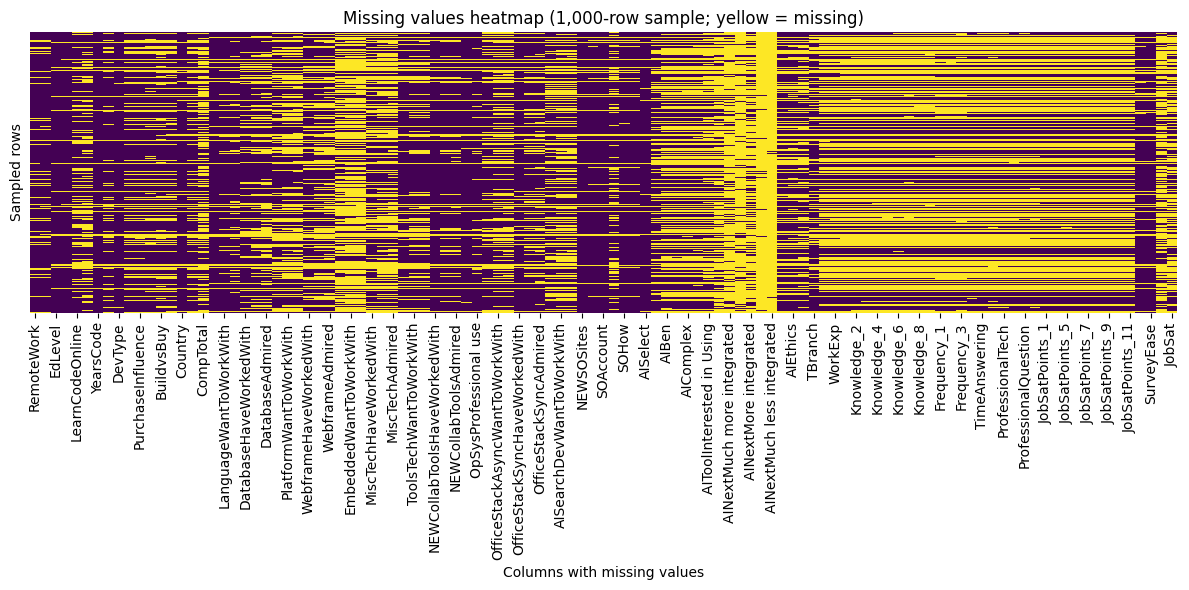

In [6]:
## Write your code here
# Task 3: visualize missing values using a heatmap (seaborn)
# The full 65k x 114 matrix is too large to render, so we plot a random
# sample of 1,000 rows for the columns that contain missing values.
cols_with_missing = df.columns[df.isna().any()].tolist()
sample = df[cols_with_missing].isna().sample(n=1000, random_state=1)

plt.figure(figsize=(12, 6))
sns.heatmap(sample, cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing values heatmap (1,000-row sample; yellow = missing)')
plt.xlabel('Columns with missing values')
plt.ylabel('Sampled rows')
plt.tight_layout()
plt.show()

##### Task 4: Count the number of missing rows for a specific column (e.g., `Employment`).


In [7]:
## Write your code here
# Task 4: count the number of missing rows for a specific column (Employment)
employment_missing = df['Employment'].isna().sum()
print("Missing rows in 'Employment':", employment_missing)

# NOTE: in this dataset the Employment column is fully populated (0 missing),
# so nothing has to be imputed there. EdLevel (4,653 missing) is a column
# where imputation actually changes something - used as demo in the next tasks.

Missing rows in 'Employment': 0


### 4. Imputing Missing Values
##### Task 5: Identify the most frequent (majority) value in a specific column (e.g., `Employment`).


In [8]:
## Write your code here
# Task 5: most frequent (majority) value in the Employment column
most_frequent_employment = df['Employment'].mode()[0]
print("Most frequent Employment value:", most_frequent_employment)
print("Occurrences:", (df['Employment'] == most_frequent_employment).sum())

Most frequent Employment value: Employed, full-time
Occurrences: 39046


##### Task 6: Impute missing values in the `Employment` column with the most frequent value.



In [9]:
## Write your code here
# Task 6: impute missing values in Employment with the most frequent value
# (Employment has 0 missing values, so this is a safe no-op for that column)
df['Employment'] = df['Employment'].fillna(most_frequent_employment)
print("Employment missing after imputation:", df['Employment'].isna().sum())

# Demonstration on a column that genuinely has missing values: EdLevel
most_frequent_edlevel = df['EdLevel'].mode()[0]
print("\nDemo - most frequent EdLevel:", most_frequent_edlevel)
print("EdLevel missing before imputation:", df['EdLevel'].isna().sum())
df['EdLevel'] = df['EdLevel'].fillna(most_frequent_edlevel)
print("EdLevel missing after imputation:", df['EdLevel'].isna().sum())

Employment missing after imputation: 0

Demo - most frequent EdLevel: Bachelor’s degree (B.A., B.S., B.Eng., etc.)
EdLevel missing before imputation: 4653
EdLevel missing after imputation: 0


### 5. Visualizing Imputed Data
##### Task 7: Visualize the distribution of a column after imputation (e.g., `Employment`).


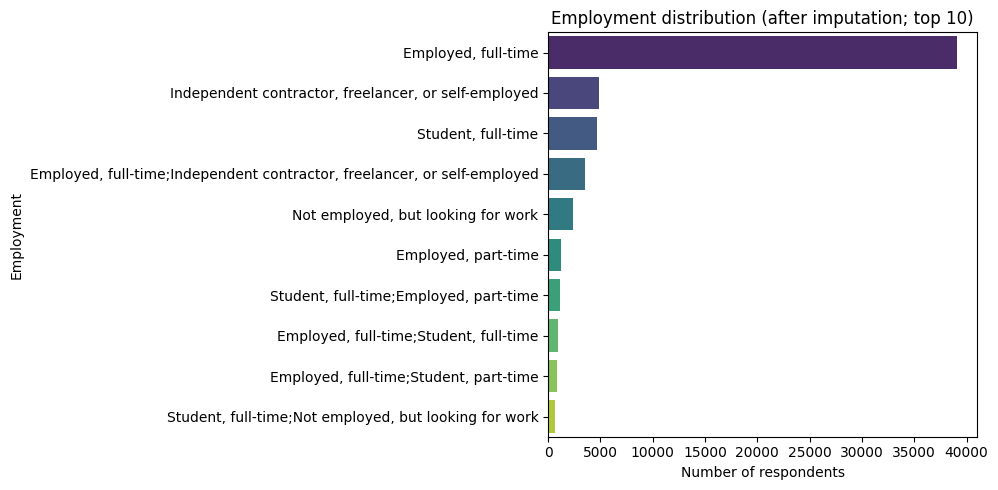

In [10]:
## Write your code here
# Task 7: visualize the distribution of Employment after imputation
plt.figure(figsize=(10, 5))
employment_counts = df['Employment'].value_counts().head(10)
sns.barplot(x=employment_counts.values, y=employment_counts.index,
             hue=employment_counts.index, palette='viridis', legend=False)
plt.title('Employment distribution (after imputation; top 10)')
plt.xlabel('Number of respondents')
plt.ylabel('Employment')
plt.tight_layout()
plt.show()

### Summary


In this lab, you:
- Loaded the dataset into a pandas DataFrame.
- Identified missing values across all columns.
- Quantified missing values in specific columns.
- Imputed missing values in a categorical column using the most frequent value.
- Visualized the imputed data for better understanding.
  


Copyright © IBM Corporation. All rights reserved.
